In [1]:
import pandas as pd
import joblib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BASE_DIR = Path("..")

df = pd.read_csv(BASE_DIR / "data" / "processed" / "cleaned_car_data.csv")

X = df.drop("Selling_Price", axis=1)
y = df["Selling_Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = joblib.load(BASE_DIR / "models" / "best_model.pkl")

y_pred = model.predict(X_test)

print("Test samples:", len(X_test))
print("Model loaded successfully")

Test samples: 60
Model loaded successfully


In [2]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R² Score: {r2:.3f}")

MAE: 1.411
RMSE: 2.429
R² Score: 0.771


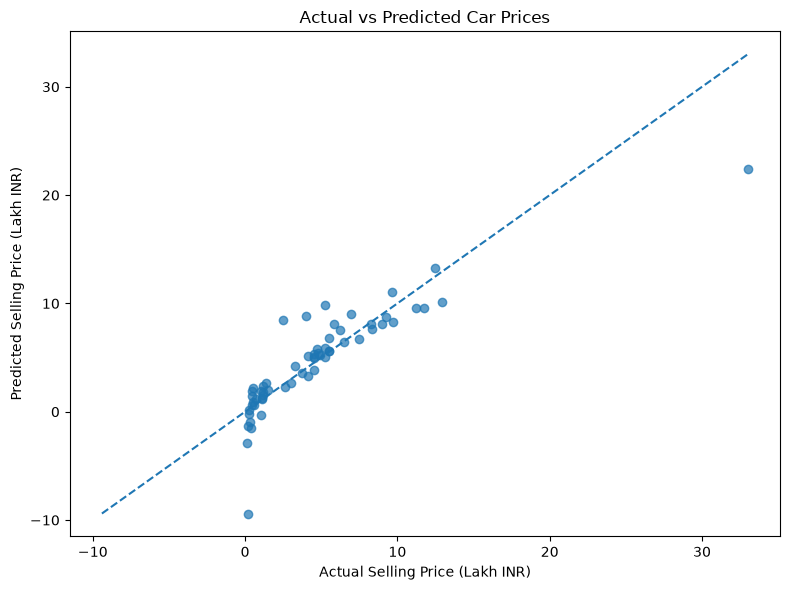

In [3]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Selling Price (Lakh INR)")
plt.ylabel("Predicted Selling Price (Lakh INR)")
plt.title("Actual vs Predicted Car Prices")
plt.tight_layout()

plt.savefig(
    BASE_DIR / "reports" / "figures" / "actual_vs_predicted_evaluation.png",
    dpi=300
)

plt.show()

In [4]:
evaluation_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score"],
    "Value": [mae, rmse, r2]
})

display(evaluation_results)

REPORT_PATH = BASE_DIR / "reports"
REPORT_PATH.mkdir(parents=True, exist_ok=True)

evaluation_results.to_csv(
    REPORT_PATH / "final_evaluation.csv",
    index=False
)

,Metric,Value
0,MAE,1.410599
1,RMSE,2.429453
2,R2 Score,0.770994
